# Medical-device sales: churn prediction and revenue forecasting

Two planning questions for a B2B medical-device business, answered on synthetic data from `generate_data.py`:

1. **Churn:** which accounts are most likely to be lost in the next 90 days?
2. **Revenue:** what will monthly revenue be over the next six months, and how confident should we be?

The logic lives in `churn_model.py`, `revenue_forecast.py` and `analysis.py`; this notebook runs it and shows the results.

In [1]:
import json

import pandas as pd
from IPython.display import Image, display

from analysis import run_analysis

pd.set_option("display.precision", 3)
summary = run_analysis()
churn, revenue = summary["churn"], summary["revenue"]
pd.Series(churn["split"])

train_rows                                                     750
validation_rows                                                280
test_rows                                                      280
train_snapshots         [2021-01-01 00:00:00, 2023-01-20 00:00:00]
validation_snapshots    [2023-04-21 00:00:00, 2024-01-25 00:00:00]
test_snapshots          [2024-01-26 00:00:00, 2024-10-31 00:00:00]
label_embargo_days                                              90
test_churn_rate                                              0.225
dtype: object

## Churn: model selection on the validation period

Snapshots are split chronologically (60/20/20). Training rows whose 90-day outcome window is still open when validation starts are dropped, so the model only learns from labels that would have been observed. Candidates are compared on validation log loss, which rewards calibrated probabilities as well as ranking.

In [2]:
pd.read_csv("metrics/churn_model_selection.csv")

,model,params,roc_auc,pr_auc,brier,log_loss
0,logistic_regression,"{""C"": 0.01}",0.851,0.705,0.137,0.432
1,logistic_regression,"{""C"": 0.1}",0.850,0.695,0.127,0.401
2,logistic_regression,"{""C"": 1.0}",0.846,0.683,0.130,0.404
3,logistic_regression,"{""C"": 10.0}",0.845,0.680,0.131,0.405
4,gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 100, ""max_...",0.822,0.630,0.141,0.435
5,gradient_boosting,"{""learning_rate"": 0.05, ""max_iter"": 200, ""max_...",0.811,0.614,0.147,0.455
6,gradient_boosting,"{""learning_rate"": 0.03, ""max_iter"": 300, ""max_...",0.830,0.658,0.136,0.421
7,gradient_boosting,"{""learning_rate"": 0.1, ""max_iter"": 100, ""max_l...",0.800,0.602,0.165,0.522


## Churn: test-period performance

Because the data are synthetic, the generator's true churn probability is known. Its score on the test period is the best any model could achieve on these rows.

In [3]:
ci = churn["uncertainty_95pct"]
rows = []
for name, m in churn["test"].items():
    row = {"model": name, **m}
    if name in ci:
        row["roc_auc_95ci"] = f"{ci[name]['roc_auc']['low_2.5']:.3f} to {ci[name]['roc_auc']['high_97.5']:.3f}"
    if name in churn["top_decile"]:
        row["top_decile_precision"] = churn["top_decile"][name]["precision"]
    rows.append(row)
display(pd.DataFrame(rows).set_index("model"))
diff = ci["roc_auc_difference_logistic_regression_minus_gradient_boosting"]
print(f"Paired ROC-AUC difference, logistic minus boosting: {diff['low_2.5']:.3f} to {diff['high_97.5']:.3f} (95% CI)")

,roc_auc,pr_auc,brier,log_loss,roc_auc_95ci,top_decile_precision
model,,,,,,
prevalence_baseline,0.500,0.225,0.174,0.533,NaN,NaN
logistic_regression,0.790,0.577,0.136,0.426,0.723 to 0.851,0.643
gradient_boosting,0.730,0.483,0.156,0.481,0.657 to 0.799,0.500
oracle_true_probability,0.792,0.579,0.136,0.424,NaN,0.643


Paired ROC-AUC difference, logistic minus boosting: 0.026 to 0.096 (95% CI)


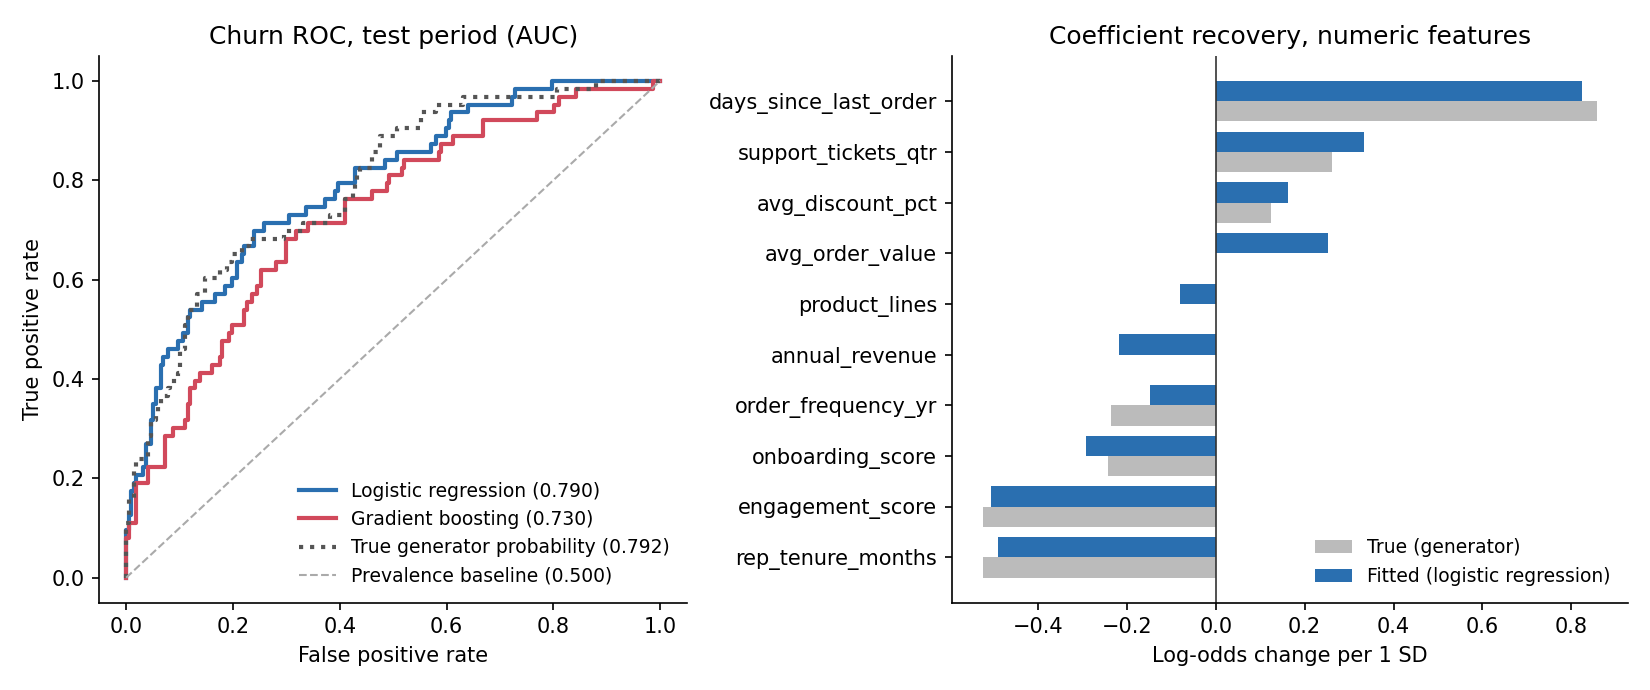

,bin,mean_predicted,observed_rate,model
0,1,0.036,0.018,logistic_regression
1,2,0.084,0.143,logistic_regression
2,3,0.164,0.143,logistic_regression
3,4,0.272,0.268,logistic_regression
4,5,0.575,0.554,logistic_regression
5,1,0.045,0.089,gradient_boosting
6,2,0.085,0.089,gradient_boosting
7,3,0.139,0.179,gradient_boosting
8,4,0.255,0.304,gradient_boosting
9,5,0.568,0.464,gradient_boosting


In [4]:
display(Image("figures/roc_curves.png"))
pd.read_csv("metrics/churn_calibration.csv")

Logistic regression essentially matches the true probability on this test period, and gradient boosting trails it. That is the expected result when the true relationship is linear in the log-odds: the extra flexibility of trees only adds variance. All seven true churn drivers are recovered with the correct sign.

In [5]:
pd.Series(churn["coefficient_recovery"])

true_drivers                      7.000
true_drivers_with_correct_sign    7.000
correlation_fitted_vs_true        0.881
dtype: float64

## Revenue: rolling-origin backtest

Revenue compounds by a percentage each month and its seasonal swing scales with its level, so the structured models work on log revenue. Each method forecasts six months ahead from seven origins inside the first 36 months; the method with the lowest mean MAPE among those whose fits all converged is selected. The last six months are held out until then.

In [6]:
pd.DataFrame(revenue["backtest"]).set_index("method")

,mape,rmse,coverage_95,all_fits_converged,n_forecasts
method,,,,,
seasonal_naive,0.425,255221.333,0.000,True,42
drift,0.188,130547.468,0.500,True,42
ets_log,0.068,45571.338,0.310,True,42
ets_damped_log,0.076,52012.092,0.524,True,42
sarima_log,0.067,43760.925,0.810,True,42
trend_fourier_log,0.065,44811.116,0.905,True,42


## Revenue: untouched six-month holdout

Selected by backtest: trend_fourier_log


,mape,rmse,coverage_95,all_fits_converged,n_forecasts
method,,,,,
seasonal_naive,0.443,406718.914,0.000,True,6
drift,0.226,266515.290,0.333,True,6
ets_log,0.055,67798.790,0.833,True,6
ets_damped_log,0.052,66596.383,0.833,True,6
sarima_log,0.059,62572.026,1.000,True,6
trend_fourier_log,0.062,75933.069,0.833,True,6


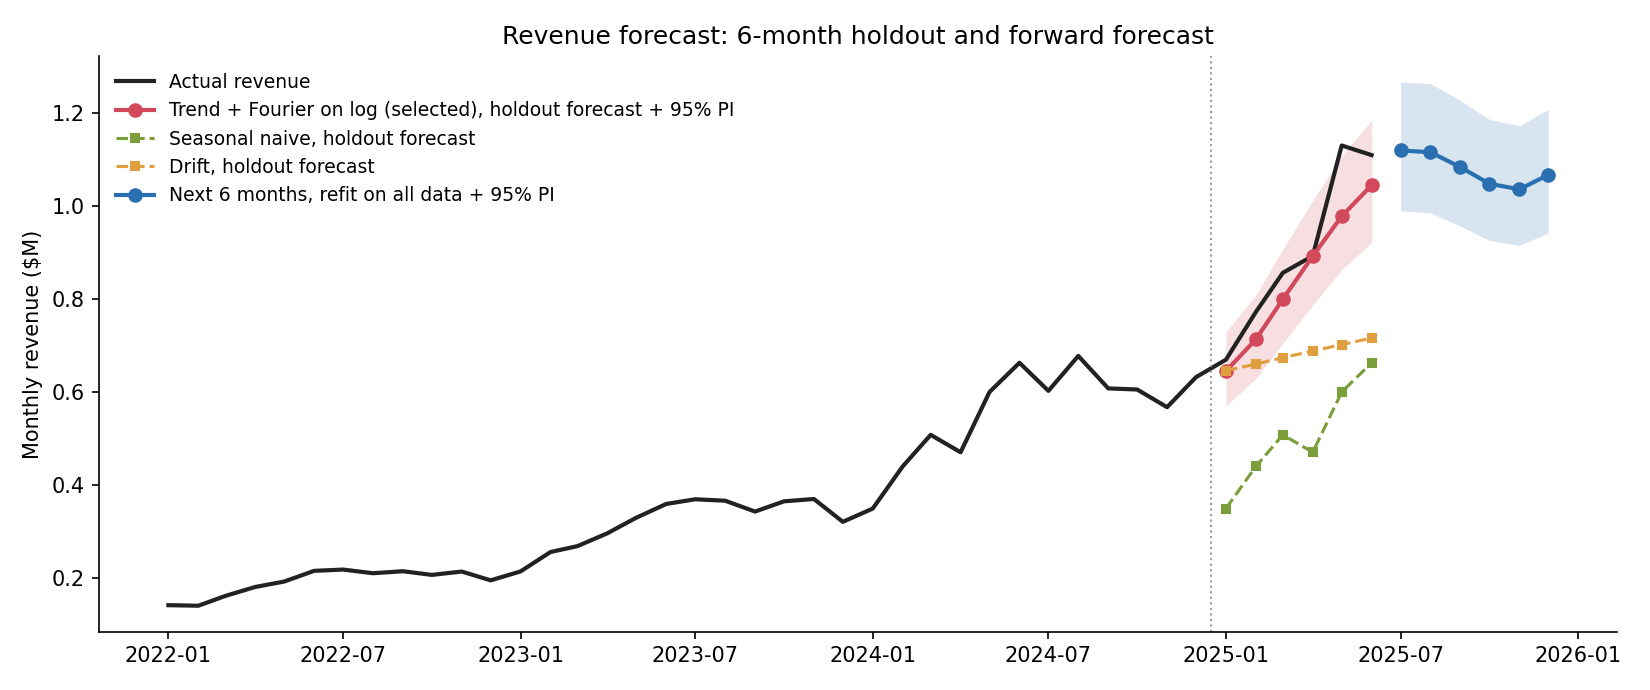

,month,forecast,lower_95,upper_95
0,2025-07,1.120e+06,990096.648,1.266e+06
1,2025-08,1.116e+06,985254.251,1.263e+06
2,2025-09,1.084e+06,956987.725,1.227e+06
3,2025-10,1.048e+06,925903.642,1.186e+06
4,2025-11,1.036e+06,915237.805,1.173e+06
5,2025-12,1.067e+06,942241.260,1.208e+06


In [7]:
print("Selected by backtest:", revenue["selected_method"])
display(pd.DataFrame(revenue["holdout"]).set_index("method"))
display(Image("figures/revenue_forecast.png"))
pd.read_csv("metrics/revenue_forward_forecast.csv")

## Takeaways

* A regularized logistic regression ranks churn risk about as well as the true model allows; flagging the top 10% of accounts finds churners at close to three times the base rate.
* For revenue, modeling growth and seasonality on the log scale cuts holdout error from 23% MAPE (best baseline) to about 6%, and every model fit converges.
* The test period has 280 accounts and the revenue holdout six months, so the intervals around these numbers are wide.